# Oculus — Plain BCE CNN | Ben Graham vs imbalanced training

**Kaggle-ready research notebook.** Two independent runs, the same CNN and plain BCE loss:

- **Run 1:** balanced training set with Ben Graham images, normal DataLoader (no 60/40 sampling).
- **Run 2:** original imbalanced training set, approximately **60% non-DR / 40% DR per batch** (19/13 for batch size 32), and **repeat-aware DR augmentation**.

Both runs must use the **same validation set, labels, patient grouping, and validation preprocessing** to be directly comparable. Changing Ben Graham preprocessing and balancing together makes a *combined* comparison, not an isolated causal test of imbalance alone.

**Important:** Kaggle dataset file names and archive layout cannot be verified from the dataset landing page. The first cells print what is mounted and make you explicitly select the correct manifest and image roots. They fail loudly instead of silently selecting a wrong dataset. Use *Add Input* in Kaggle and attach `nithyamajeti/v16-balanced-normalizedben-graham-and-non`.

This notebook **does not run a test-set evaluation automatically**. It records validation history and saves best checkpoints. Run the held-out test only after the final model/threshold protocol is fixed. GPU quota can stop a Kaggle run even when AUROC patience has not been reached.

In [1]:

import os
import glob
import zipfile

# Find ZIP files attached to the Kaggle notebook
zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)

print("ZIP files found:")
for path in zip_files:
    print(path)

# Extract notebook output ZIP files
EXTRACT_DIR = "/kaggle/working/extracted_data"
os.makedirs(EXTRACT_DIR, exist_ok=True)

for zip_path in zip_files:
    print(f"\nExtracting: {zip_path}")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Extraction complete!")

print("\nExtracted files:")
for root, dirs, files in os.walk(EXTRACT_DIR):
    print(root, ":", len(files), "files")
    if root.count(os.sep) >= 7:
        dirs[:] = []

ZIP files found:
/kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/_output_.zip

Extracting: /kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/_output_.zip
Extraction complete!

Extracted files:
/kaggle/working/extracted_data : 1 files
/kaggle/working/extracted_data/__pycache__ : 0 files
/kaggle/working/extracted_data/processed : 0 files
/kaggle/working/extracted_data/processed/test : 6491 files
/kaggle/working/extracted_data/processed/train : 30287 files
/kaggle/working/extracted_data/processed/unused : 45578 files
/kaggle/working/extracted_data/processed/val : 6483 files
/kaggle/working/extracted_data/processed_bg : 0 files
/kaggle/working/extracted_data/processed_bg/test : 6491 files
/kaggle/working/extracted_data/processed_bg/train : 30287 files
/kaggle/working/extracted_data/processed_bg/unused : 45578 files
/kaggle/working/extracted_data/processed_bg/val : 6483 files


In [2]:
import os
import glob

print("CSV files:")
for path in glob.glob("/kaggle/working/extracted_data/**/*.csv", recursive=True):
    print(path)

print("\nImage folders:")
for path in glob.glob("/kaggle/working/extracted_data/**/processed*", recursive=True):
    if os.path.isdir(path):
        print(path)

CSV files:
/kaggle/working/extracted_data/manifest_v2.csv

Image folders:
/kaggle/working/extracted_data/processed
/kaggle/working/extracted_data/processed_bg


In [3]:

import pandas as pd

manifest = pd.read_csv(
    "/kaggle/working/extracted_data/manifest_v2.csv"
)

print("Columns:")
print(manifest.columns.tolist())

print("\nCurrent split distribution:")
print(pd.crosstab(manifest["split"], manifest["label"]))

print("\nOriginal split distribution:")
print(pd.crosstab(manifest["orig_split"], manifest["label"]))

print("\nUnused image reasons:")
print(manifest.loc[
    manifest["split"] == "unused",
    "excluded_reason"
].value_counts(dropna=False))

print("\nOriginal training images marked unused:")
print(pd.crosstab(
    manifest.loc[manifest["split"] == "unused", "orig_split"],
    manifest.loc[manifest["split"] == "unused", "label"]
))

Columns:
['filename', 'path', 'source', 'group_id', 'grade', 'label', 'orig_split', 'split', 'excluded_reason', 'processed_path', 'processed_path_bg', 'load_ok']

Current split distribution:
label       0      1
split               
test     4907   1584
train   15126  15161
unused  42223   3355
val      4892   1591

Original split distribution:
label           0      1
orig_split              
test         6709   2180
train       53724  17340
val          6715   2171

Unused image reasons:
excluded_reason
undersampled_no_DR        31908
trimmed_to_match_ratio    13670
Name: count, dtype: int64

Original training images marked unused:
label           0     1
orig_split             
test         4209   337
train       33827  2684
val          4187   334


In [4]:
import os, random, math, json, zipfile, shutil, hashlib
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 32
PATIENCE = 5
MIN_AUROC_IMPROVEMENT = 0.0  # strict AUROC improvement resets patience
LR = 1e-3
WEIGHT_DECAY = 1e-4
TARGET_SENSITIVITY = 0.90
# No fixed epoch cap. External Kaggle runtime limits can still stop a run.
MAX_EPOCHS = None
NUM_WORKERS = 2
RUN_TEST = False
DATA_ROOT = Path('/kaggle/input/v16-balanced-normalizedben-graham-and-non')
WORK_ROOT = Path('/kaggle/working/oculus_plain_bce')
WORK_ROOT.mkdir(parents=True, exist_ok=True)

# Optional: explicitly name a ZIP if Kaggle has mounted the notebook output as an archive.
# Leave None to inspect archives and extract only when needed.
ARCHIVE_TO_EXTRACT = None

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| dataset mounted:', DATA_ROOT.exists())
print('Mounted Kaggle input roots:', [str(p) for p in Path('/kaggle/input').iterdir()] if Path('/kaggle/input').exists() else [])

Device: cuda | dataset mounted: False
Mounted Kaggle input roots: ['/kaggle/input/notebooks']


## 1. Inspect attached data and safely unzip only when needed

Kaggle often exposes ZIP dataset contents already extracted. If an archive is still a `.zip`, the helper below expands it under `/kaggle/working/oculus_plain_bce/extracted/` (never writes under read-only `/kaggle/input`). Check available disk space for large image archives. It **does not** unzip every archive automatically.

In [5]:
def print_tree(root, limit=85):
    root = Path(root)
    if not root.exists():
        print('Missing:', root); return
    seen = 0
    for path in root.rglob('*'):
        if path.is_file() and (len(path.relative_to(root).parts) <= 4 or path.suffix.lower() in ('.csv', '.zip')):
            print(path.relative_to(root), f'({path.stat().st_size / 2**20:.1f} MB)')
            seen += 1
            if seen >= limit:
                print('... output truncated'); break

print_tree(DATA_ROOT)
archives = sorted(DATA_ROOT.rglob('*.zip')) if DATA_ROOT.exists() else []
print('ZIPs:', [str(p) for p in archives])

def extract_zip_safely(archive, destination):
    archive, destination = Path(archive), Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    marker = destination / f'.complete_{hashlib.sha256(str(archive).encode()).hexdigest()[:12]}'
    if marker.exists():
        print('Already extracted:', archive.name)
        return destination
    with zipfile.ZipFile(archive) as z:
        base = destination.resolve()
        for member in z.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(base):
                raise ValueError(f'Unsafe ZIP path: {member.filename}')
            if member.is_dir(): continue
            # Reject symbolic link entries
            if (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError(f'Symlink in ZIP: {member.filename}')
        z.extractall(destination)
    marker.touch()
    print('Extracted:', archive, '->', destination)
    return destination

EXTRACTED_ROOT = WORK_ROOT / 'extracted'
if ARCHIVE_TO_EXTRACT is not None:
    extract_zip_safely(ARCHIVE_TO_EXTRACT, EXTRACTED_ROOT)
# If your CSV/images live inside a ZIP: set ARCHIVE_TO_EXTRACT to the printed path and rerun this cell.

Missing: /kaggle/input/v16-balanced-normalizedben-graham-and-non
ZIPs: []


## 2. Explicitly select each manifest and image root

**Required schema:** a CSV with `split`, `label` (0 = non-DR, 1 = DR), `filename` or `processed_path`, and preferably `group_id`. For Run 1 use the **balanced Ben Graham** images; for Run 2 use the **original imbalanced** images. Run 2 must not reconstruct its training set by adding an unrelated `unused` set without verifying its original split and patient groups. If the new dataset stores different names, adapt `load_manifest` carefully.

**Action:** Run the discovery cell; then edit `BALANCED_MANIFEST`, `IMBALANCED_MANIFEST`, and the optional `*_IMAGE_ROOT` fields below. Do not proceed until the printed split/class counts match expectations. If one CSV has both versions, you may use the same manifest path but filter into separate frames first. The CSV `processed_path` in your old notebook pointed to a *different Kaggle working directory*, so this loader rebuilds paths against the actual mounted data.

In [6]:
SEARCH_ROOTS = [p for p in [DATA_ROOT, EXTRACTED_ROOT] if p.exists()]
candidates = sorted({str(f) for root in SEARCH_ROOTS for f in root.rglob('*.csv')})
for i, p in enumerate(candidates):
    try:
        print(f'[{i}] {p} | columns: {pd.read_csv(p, nrows=2).columns.tolist()}')
    except Exception as exc:
        print(f'[{i}] {p} | cannot read: {exc}')

In [7]:
BALANCED_MANIFEST = "/kaggle/working/extracted_data/balanced_bg_manifest.csv"
IMBALANCED_MANIFEST = "/kaggle/working/extracted_data/imbalanced_bg_manifest.csv"
BALANCED_IMAGE_ROOT = "/kaggle/working/extracted_data/processed_bg"
IMBALANCED_IMAGE_ROOT = "/kaggle/working/extracted_data/processed_bg"

In [8]:
def load_manifest(manifest_path, image_root=None):
    if manifest_path is None:
        raise ValueError('Select an exact BALANCED_MANIFEST and IMBALANCED_MANIFEST from the discovery output.')
    manifest_path = Path(manifest_path)
    if not manifest_path.exists(): raise FileNotFoundError(manifest_path)
    frame = pd.read_csv(manifest_path, low_memory=False)
    required = {'split', 'label'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{manifest_path.name} needs {required}, found {frame.columns.tolist()}')
    frame['split'] = frame['split'].astype(str).str.lower().str.strip().replace({'validation':'val','valid':'val'})
    frame['label'] = pd.to_numeric(frame['label'], errors='raise').astype(int)
    if not set(frame['label'].unique()).issubset({0,1}): raise ValueError('Expected binary labels 0/1')
    frame = frame[frame['split'].isin(['train','val','test'])].copy()
    if not len(frame): raise ValueError('No train/val/test rows')
    if not {'train', 'val'}.issubset(set(frame['split'])):
        raise ValueError('Must include both train and val')
    image_root = Path(image_root) if image_root else manifest_path.parent
    path_fields = [c for c in ['processed_path','relative_path','path','filename'] if c in frame.columns]
    if not path_fields: raise ValueError('CSV needs a path or filename column')
    # Construct a small lookup of image basenames only if simple paths fail.
    indexed = None
    def resolve(row):
        nonlocal indexed
        for field in path_fields:
            raw = row.get(field)
            if pd.isna(raw): continue
            raw = str(raw).replace('\\','/')
            src = Path(raw)
            possibilities = [src, image_root / raw, image_root / row['split'] / src.name,
                             manifest_path.parent / raw, image_root / src.name]
            for p in possibilities:
                if p.is_file(): return str(p)
            # Old Kaggle absolute paths are stale; try their basename in the mounted root
            if indexed is None:
                indexed = defaultdict(list)
                for p in image_root.rglob('*'):
                    if p.is_file() and p.suffix.lower() in ('.jpg','.jpeg','.png','.webp'):
                        indexed[p.name].append(p)
            matched = indexed.get(src.name, [])
            if len(matched) == 1: return str(matched[0])
            split_match = [p for p in matched if row['split'] in p.parts]
            if len(split_match) == 1: return str(split_match[0])
        raise FileNotFoundError(f'Cannot uniquely resolve image {row.get("filename", row.to_dict())}; check IMAGE_ROOT')
    frame['image_path'] = frame.apply(resolve, axis=1)
    return frame.reset_index(drop=True)


import os
import pandas as pd

ROOT = "/kaggle/working/extracted_data"

df = pd.read_csv(f"{ROOT}/manifest_v2.csv")

# Protect the current validation and test sets.
held_out = df[df["split"].isin(["val", "test"])].copy()
held_out_groups = set(held_out["group_id"].dropna())

# Existing balanced training dataset.
balanced_train = df[df["split"] == "train"].copy()

# Recover non-DR images removed by undersampling.
restored = df[
    (df["split"] == "unused")
    & (df["orig_split"] == "train")
    & (df["excluded_reason"] == "undersampled_no_DR")
    & (df["label"] == 0)
].copy()

# Exclude patient groups found in validation or test.
restored = restored[
    ~restored["group_id"].isin(held_out_groups)
].copy()

# Build the new imbalanced training dataset.
restored["split"] = "train"

imbalanced_train = pd.concat(
    [balanced_train, restored],
    ignore_index=True
)

# Keep each image's original storage folder.
imbalanced_train["storage_split"] = (
    ["train"] * len(balanced_train)
    + ["unused"] * len(restored)
)

# Create complete manifests, including unchanged validation/test.
balanced_full = df[
    df["split"].isin(["train", "val", "test"])
].copy()

balanced_full["storage_split"] = balanced_full["split"]

imbalanced_full = pd.concat(
    [imbalanced_train, held_out],
    ignore_index=True
)

imbalanced_full.loc[
    imbalanced_full["storage_split"].isna(),
    "storage_split"
] = imbalanced_full["split"]

# Point to the actual Ben Graham image files.
for frame in [balanced_full, imbalanced_full]:
    frame["processed_path"] = frame.apply(
        lambda row: os.path.join(
            ROOT,
            "processed_bg",
            row["storage_split"],
            row["filename"]
        ),
        axis=1
    )

    assert frame["processed_path"].map(os.path.isfile).all(), \
        "Missing Ben Graham images!"

    assert frame["group_id"].notna().all(), \
        "Missing group IDs!"

    assert (
        frame.groupby("group_id")["split"].nunique().max()
        == 1
    ), "Patient group overlap detected!"

# Confirm the validation and test rows are unchanged.
for split in ["val", "test"]:
    a = balanced_full[balanced_full["split"] == split]
    b = imbalanced_full[imbalanced_full["split"] == split]

    cols = ["source", "filename", "group_id", "label"]
    assert a[cols].value_counts().sort_index().equals(
        b[cols].value_counts().sort_index()
    ), f"{split} sets do not match!"

# Save the manifests.
balanced_path = f"{ROOT}/balanced_bg_manifest.csv"
imbalanced_path = f"{ROOT}/imbalanced_bg_manifest.csv"

balanced_full.to_csv(balanced_path, index=False)
imbalanced_full.to_csv(imbalanced_path, index=False)

print("BALANCED TRAINING:")
print(balanced_full.query("split == 'train'")["label"].value_counts())

print("\nIMBALANCED TRAINING:")
print(imbalanced_full.query("split == 'train'")["label"].value_counts())

print("\nManifests saved successfully!")

balanced = load_manifest(BALANCED_MANIFEST, BALANCED_IMAGE_ROOT)
imbalanced = load_manifest(IMBALANCED_MANIFEST, IMBALANCED_IMAGE_ROOT)
for title, frame in [('Balanced Ben Graham',balanced),('Original imbalanced',imbalanced)]:
    print('\n',title,'\n',pd.crosstab(frame['split'], frame['label']))
    if 'group_id' in frame:
        conflicts = frame.groupby('group_id')['split'].nunique().gt(1).sum()
        if conflicts: raise ValueError(f'{title}: {conflicts} group IDs overlap splits!')
        print('Group overlap:', conflicts)
    else: print('WARNING: no group_id; patient-level leakage cannot be verified.')
    assert frame[frame.split.eq('train')].label.nunique()==2
    assert frame[frame.split.eq('val')].label.nunique()==2

# Paired experiments must use the same validation images. Compare identity + labels,
# not paths, since Ben Graham and raw versions can share image identities.
identity_col = 'group_id' if 'group_id' in balanced.columns and 'group_id' in imbalanced.columns else 'filename'
if identity_col not in balanced.columns or identity_col not in imbalanced.columns:
    raise ValueError('Need a shared group_id or filename to verify matching validation sets')
val_a = balanced.query("split == 'val'")[[identity_col,'label']].value_counts().sort_index()
val_b = imbalanced.query("split == 'val'")[[identity_col,'label']].value_counts().sort_index()
if not val_a.equals(val_b):
    raise ValueError('Validation identity/labels differ! Do not compare these runs until aligned.')
print('Validation identities/labels aligned:', len(val_a))

BALANCED TRAINING:
label
1    15161
0    15126
Name: count, dtype: int64

IMBALANCED TRAINING:
label
0    40672
1    15161
Name: count, dtype: int64

Manifests saved successfully!

 Balanced Ben Graham 
 label      0      1
split              
test    4907   1584
train  15126  15161
val     4892   1591
Group overlap: 0

 Original imbalanced 
 label      0      1
split              
test    4907   1584
train  40672  15161
val     4892   1591
Group overlap: 0
Validation identities/labels aligned: 3652


## 3. CNN, transforms and repeat-aware sampling

For batch size 32, **19 non-DR + 13 DR = 59.4% / 40.6%**. Applying the sampler only depends on the **actual training class ratio**, not on the name of the dataset. A 45–55% range counts as approximately balanced (configurable). For imbalanced training, sampled image indices are tracked across **all epochs**. Any DR image repeated after its first use receives a fresh random augmentation. Validation never receives random augmentation or balanced sampling.

*Augmentation is mild rotation / horizontal flip / small colour adjustments. Retinal laterality and disease grading should be reviewed with the project mentor before using flips clinically.*

In [9]:
class BaselineCNN(nn.Module):
    def __init__(self, channels=(32,64,128,256), dropout=0.3):
        super().__init__()
        self.blocks = nn.ModuleList()
        prev = 3
        for width in channels:
            self.blocks.append(nn.Sequential(
                nn.Conv2d(prev, width, kernel_size=3, padding=1),
                nn.BatchNorm2d(width), nn.ReLU(), nn.MaxPool2d(2)))
            prev = width
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], 1)
    def forward(self, x):
        for block in self.blocks: x = block(x)
        return self.fc(self.dropout(self.pool(x).flatten(1)))

# Input images in the linked dataset are described as already normalized.
# Keep ToTensor() as the baseline to avoid applying unknown mean/std twice.
BASE_TRANSFORM = transforms.ToTensor()
REPEAT_DR_AUGMENT = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
])

class RetinalDataset(Dataset):
    def __init__(self, frame, augment_repeated_dr=False):
        self.frame = frame.reset_index(drop=True).copy()
        self.augment_repeated_dr = augment_repeated_dr
    def __len__(self): return len(self.frame)
    def __getitem__(self, request):
        if isinstance(request, tuple):
            index, repeated = request
        else:
            index, repeated = request, False
        row = self.frame.iloc[int(index)]
        with Image.open(row.image_path) as raw:
            im = raw.convert('RGB')
        if repeated and self.augment_repeated_dr and int(row.label)==1:
            im = REPEAT_DR_AUGMENT(im)
        x = BASE_TRANSFORM(im)
        y = torch.tensor(float(row.label), dtype=torch.float32)
        return x, y

class RepeatAwareBatchSampler(Sampler):
    # Creates 19/13 batches and flags repeated minority examples for augmentation.
    def __init__(self, labels, batch_size=32, non_dr_share=0.60, seed=42):
        self.labels = np.asarray(labels, dtype=int)
        self.non_dr = np.flatnonzero(self.labels==0)
        self.dr = np.flatnonzero(self.labels==1)
        if not len(self.non_dr) or not len(self.dr): raise ValueError('Need both classes')
        self.batch_size = batch_size
        self.n_non = round(batch_size * non_dr_share)
        self.n_dr = batch_size - self.n_non
        if min(self.n_non, self.n_dr) < 1: raise ValueError('Invalid batch proportions')
        self.n_batches = max(math.ceil(len(self.non_dr)/self.n_non),
                             math.ceil(len(self.dr)/self.n_dr))
        self.rng = np.random.default_rng(seed)
        self.use_counts = Counter()  # tracks dataset indices over all epochs
        self.epoch = 0
        self.last_epoch_stats = {}
    def __len__(self): return self.n_batches
    def __iter__(self):
        self.epoch += 1
        pools = {0:self.non_dr, 1:self.dr}
        order = {k:self.rng.permutation(v).tolist() for k,v in pools.items()}
        cursors = {0:0,1:0}
        repeat_dr=0; unique_dr=set(); non_total=0; dr_total=0
        for _ in range(self.n_batches):
            batch=[]
            for cls, count in ((0,self.n_non),(1,self.n_dr)):
                for _ in range(count):
                    if cursors[cls] >= len(order[cls]):
                        order[cls] = self.rng.permutation(pools[cls]).tolist()
                        cursors[cls] = 0
                    idx = int(order[cls][cursors[cls]])
                    cursors[cls] += 1
                    repeated = cls == 1 and self.use_counts[idx] > 0
                    self.use_counts[idx] += 1
                    if cls == 1:
                        dr_total += 1; unique_dr.add(idx); repeat_dr += int(repeated)
                    else: non_total += 1
                    batch.append((idx, repeated))
            self.rng.shuffle(batch)
            yield batch
        self.last_epoch_stats = {'epoch':self.epoch, 'non_dr_draws':non_total,
                                 'dr_draws':dr_total, 'unique_dr_seen_this_epoch':len(unique_dr),
                                 'repeated_dr_draws_augmented':repeat_dr,
                                 'total_unique_indices_ever':len(self.use_counts)}

BALANCE_TOLERANCE = 0.05  # 45-55% each -> balanced. 60/40 considered imbalanced.
def make_loaders(frame):
    train_frame = frame[frame.split.eq('train')].copy()
    val_frame = frame[frame.split.eq('val')].copy()
    pos_share = float(train_frame.label.mean())
    is_imbalanced = abs(pos_share-0.5) > BALANCE_TOLERANCE
    sampler = None
    if is_imbalanced:
        sampler = RepeatAwareBatchSampler(train_frame.label, BATCH_SIZE, 0.60, SEED)
        train_loader = DataLoader(RetinalDataset(train_frame, augment_repeated_dr=True),
                                  batch_sampler=sampler, num_workers=NUM_WORKERS,
                                  pin_memory=torch.cuda.is_available())
    else:
        train_loader = DataLoader(RetinalDataset(train_frame), batch_size=BATCH_SIZE,
                                  shuffle=True, num_workers=NUM_WORKERS,
                                  pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(RetinalDataset(val_frame), batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=NUM_WORKERS,
                            pin_memory=torch.cuda.is_available())
    print(f'train DR share={pos_share:.2%} | imbalance detected={is_imbalanced} | sampler={sampler is not None}')
    if sampler: print(f'Batch composition: {sampler.n_non} non-DR, {sampler.n_dr} DR')
    return train_loader, val_loader, sampler

## 4. Metrics, AUROC-only early stopping and best checkpoint

The training loop uses `while True`, **not a fixed number of epochs**. Patience resets **only** when validation AUROC strictly improves. Other metrics and validation loss are recorded but never affect stopping. The best epoch's model is saved to disk immediately, and later restored. If AUROC cannot be computed (a validation split has just one class), training stops with an explicit error. Models could run indefinitely if AUROC keeps improving, so use Kaggle runtime limits as the practical external cutoff.

In [10]:
def collect_predictions(model, loader, criterion):
    model.eval(); all_y=[]; all_probs=[]; loss_sum=0.0; count=0
    with torch.no_grad():
        for images, labels in loader:
            images=images.to(device,non_blocking=True)
            labels=labels.to(device,non_blocking=True)
            logits=model(images).squeeze(1)
            loss=criterion(logits,labels)
            probs=torch.sigmoid(logits)
            loss_sum += float(loss.item())*len(labels)
            count += len(labels)
            all_y.append(labels.cpu().numpy()); all_probs.append(probs.cpu().numpy())
    return np.concatenate(all_y), np.concatenate(all_probs), loss_sum/count

def metrics_at_threshold(y,p,threshold=0.5):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'sensitivity':tp/max(1,tp+fn), 'specificity':tn/max(1,tn+fp),
            'precision':precision_score(y,pred,zero_division=0),
            'f1':f1_score(y,pred,zero_division=0),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}

def choose_threshold(y,p,target=0.90):
    fpr,tpr,thresholds=roc_curve(y,p)
    possible=np.where((tpr>=target) & np.isfinite(thresholds))[0]
    if len(possible)==0: return float(np.nextafter(float(np.min(p)), -np.inf))
    # max specificity among candidate thresholds; largest threshold breaks ties
    best=possible[np.lexsort((-thresholds[possible],fpr[possible]))][0]
    return float(thresholds[best])

def train_one_epoch(model, loader, criterion, optimizer):
    model.train(); total=0.; seen=0
    for images,labels in loader:
        images=images.to(device,non_blocking=True)
        labels=labels.to(device,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits=model(images).squeeze(1)
        loss=criterion(logits,labels)
        loss.backward(); optimizer.step()
        total+=float(loss.item())*len(labels); seen+=len(labels)
    return total/seen

def train_run(name, frame):
    output=WORK_ROOT/name; output.mkdir(parents=True,exist_ok=True)
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    train_loader,val_loader,sampler=make_loaders(frame)
    model=BaselineCNN().to(device)
    criterion=nn.BCEWithLogitsLoss()
    optimizer=torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history=[]; best_auc=-np.inf; best_epoch=None; stale=0; epoch=0
    checkpoint=output/'best_model.pt'
    while True:
        epoch+=1
        train_loss=train_one_epoch(model,train_loader,criterion,optimizer)
        y,p,val_loss=collect_predictions(model,val_loader,criterion)
        if np.unique(y).size<2: raise RuntimeError('Validation data must contain both DR and non-DR')
        val_auc=float(roc_auc_score(y,p)); pr_auc=float(average_precision_score(y,p))
        at05=metrics_at_threshold(y,p,0.5)
        row={'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
             'auroc':val_auc,'pr_auc':pr_auc,
             **{k:at05[k] for k in ('sensitivity','specificity','precision','f1')}}
        history.append(row)
        print(f'{name} epoch={epoch} train_loss={train_loss:.4f} val_loss={val_loss:.4f} '
              f'AUROC={val_auc:.4f} sens@0.5={at05["sensitivity"]:.4f} '
              f'spec@0.5={at05["specificity"]:.4f}', flush=True)
        if sampler:
            print('  sampler:',sampler.last_epoch_stats,flush=True)
            pd.DataFrame([{'image_index':i,'times_seen':count,'label':int(train_loader.dataset.frame.iloc[i].label)}
                          for i,count in sampler.use_counts.items()]).to_csv(output/'sampling_counts.csv',index=False)
        # Early stopping checks ONLY validation AUROC, never validation loss.
        if val_auc > best_auc + MIN_AUROC_IMPROVEMENT:
            best_auc=val_auc; best_epoch=epoch; stale=0
            torch.save({'model_state':model.state_dict(),'epoch':epoch,'val_auroc':val_auc,
                        'seed':SEED,'run':name,'threshold_for_90pct_sensitivity':choose_threshold(y,p,TARGET_SENSITIVITY)},
                       checkpoint)
            pd.DataFrame({'y_true':y,'probability':p}).to_csv(output/'best_val_predictions.csv',index=False)
            print('  New best AUROC! checkpoint saved.')
        else:
            stale+=1
            print(f'  AUROC not improved: {stale}/{PATIENCE}')
        pd.DataFrame(history).to_csv(output/'history.csv',index=False)
        if stale>=PATIENCE:
            print(f'  Early stopping: {PATIENCE} consecutive epochs without AUROC improvement.');break
        if MAX_EPOCHS is not None and epoch>=MAX_EPOCHS:
            print('  Optional external epoch limit reached.');break
    saved=torch.load(checkpoint,map_location=device,weights_only=True)
    model.load_state_dict(saved['model_state'])
    # Best model evaluation at the SAME validation set after restoring checkpoint.
    y,p,_=collect_predictions(model,val_loader,criterion)
    t90=choose_threshold(y,p,TARGET_SENSITIVITY)
    summary={'run':name,'best_epoch':best_epoch,'best_validation_auroc':best_auc,
             'validation_pr_auc':float(average_precision_score(y,p)),
             'at_0_5':metrics_at_threshold(y,p,0.5),
             'threshold_for_90pct_sensitivity':t90,
             'at_90pct_sensitivity':metrics_at_threshold(y,p,t90),
             'train_class_counts':frame.query("split=='train'").label.value_counts().to_dict(),
             'seed':SEED,'batch_size':BATCH_SIZE,'patience':PATIENCE}
    with open(output/'summary.json','w') as f: json.dump(summary,f,indent=2)
    return summary, pd.DataFrame(history), (y,p), output

## 5. Reporting figures (saved as PNG and CSV)

Each run saves training/validation loss, AUROC, PR-AUC, sensitivity, specificity, precision, and F1 across epochs, plus ROC curve, precision-recall curve, and confusion matrix from the *best* checkpoint. Threshold-dependent history is shown at **0.5**; the final summary also reports metrics at a validation-selected 90%-sensitivity threshold.

In [11]:
def save_figures(name, history, val_predictions, summary, output):
    y,p=val_predictions
    fig,axes=plt.subplots(2,2,figsize=(13,9))
    axes[0,0].plot(history.epoch,history.train_loss,label='Training loss')
    axes[0,0].plot(history.epoch,history.val_loss,label='Validation loss')
    axes[0,0].set_title('Loss');axes[0,0].legend()
    axes[0,1].plot(history.epoch,history.auroc,label='AUROC')
    axes[0,1].plot(history.epoch,history.pr_auc,label='PR-AUC')
    axes[0,1].set_title('Validation ranking metrics');axes[0,1].legend()
    axes[1,0].plot(history.epoch,history.sensitivity,label='Sensitivity @ 0.5')
    axes[1,0].plot(history.epoch,history.specificity,label='Specificity @ 0.5')
    axes[1,0].set_title('Class metrics @ threshold 0.5');axes[1,0].legend()
    axes[1,1].plot(history.epoch,history.precision,label='Precision @ 0.5')
    axes[1,1].plot(history.epoch,history.f1,label='F1 @ 0.5')
    axes[1,1].set_title('Prediction metrics @ threshold 0.5');axes[1,1].legend()
    for ax in axes.flat: ax.set_xlabel('Epoch');ax.grid(alpha=0.25)
    fig.suptitle(f'{name} | best epoch {summary["best_epoch"]} | AUROC {summary["best_validation_auroc"]:.4f}')
    fig.tight_layout();fig.savefig(output/'training_metrics.png',dpi=160);plt.show();plt.close(fig)

    fpr,tpr,_=roc_curve(y,p);prec,rec,_=precision_recall_curve(y,p)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].plot(fpr,tpr,label=f'AUROC = {roc_auc_score(y,p):.4f}')
    axes[0].plot([0,1],[0,1],'--',alpha=.4)
    axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curve')
    axes[0].legend()
    axes[1].plot(rec,prec,label=f'AP = {average_precision_score(y,p):.4f}')
    axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curve')
    axes[1].legend()
    fig.tight_layout();fig.savefig(output/'roc_pr_curves.png',dpi=160);plt.show();plt.close(fig)

    threshold=summary['threshold_for_90pct_sensitivity']
    cm=confusion_matrix(y,(p>=threshold).astype(int),labels=[0,1])
    fig,ax=plt.subplots(figsize=(5,4));ax.imshow(cm,cmap='Blues')
    for (i,j),num in np.ndenumerate(cm):ax.text(j,i,str(num),ha='center',va='center')
    ax.set_xticks([0,1],['Non-DR','DR']);ax.set_yticks([0,1],['Non-DR','DR'])
    ax.set(xlabel='Predicted',ylabel='Actual',title=f'Confusion matrix | threshold {threshold:.3f}')
    fig.tight_layout();fig.savefig(output/'confusion_matrix.png',dpi=160);plt.show();plt.close(fig)

## 6. Execute Run 1 and Run 2

**Run 1** must really contain balanced Ben Graham images (look at the printed counts). **Run 2** must really contain unbalanced original training data. The sampler activates only if the measured training DR share is outside 45–55%. We require that Run 2 is genuinely imbalanced; if not, it raises an error rather than claiming to have performed the experiment. Run 1 will not use repeat-aware augmentation.

In [12]:

BALANCE_TOLERANCE = 0.05

balanced_share = balanced.query("split == 'train'").label.mean()
imbalanced_share = imbalanced.query("split == 'train'").label.mean()

assert abs(balanced_share - 0.5) <= BALANCE_TOLERANCE
assert abs(imbalanced_share - 0.5) > BALANCE_TOLERANCE

print(f"Balanced dataset: {balanced_share:.2%} DR")
print(f"Imbalanced dataset: {imbalanced_share:.2%} DR")

RUN_SMOKE_TEST = False

if RUN_SMOKE_TEST:
    for name, frame in [
        ("balanced", balanced),
        ("imbalanced", imbalanced)
    ]:
        loader, _, sampler = make_loaders(frame)
        images, labels = next(iter(loader))

        dr = int(labels.sum().item())
        non_dr = len(labels) - dr

        print(f"{name}: shape={tuple(images.shape)}, DR={dr}, non-DR={non_dr}")

        assert len(labels) == BATCH_SIZE
        assert torch.isfinite(images).all()

        if sampler is not None:
            assert dr == sampler.n_dr
            assert non_dr == sampler.n_non

    print("Smoke tests passed!")


Balanced dataset: 50.06% DR
Imbalanced dataset: 27.15% DR



Starting: run1_balanced_ben_graham
train DR share=50.06% | imbalance detected=False | sampler=False
run1_balanced_ben_graham epoch=1 train_loss=0.6640 val_loss=0.6234 AUROC=0.6802 sens@0.5=0.5116 spec@0.5=0.7449
  New best AUROC! checkpoint saved.
run1_balanced_ben_graham epoch=2 train_loss=0.6364 val_loss=2.2267 AUROC=0.6695 sens@0.5=1.0000 spec@0.5=0.0000
  AUROC not improved: 1/5
run1_balanced_ben_graham epoch=3 train_loss=0.6223 val_loss=2.9621 AUROC=0.6280 sens@0.5=1.0000 spec@0.5=0.0004
  AUROC not improved: 2/5
run1_balanced_ben_graham epoch=4 train_loss=0.6107 val_loss=0.6349 AUROC=0.6780 sens@0.5=0.0295 spec@0.5=0.9982
  AUROC not improved: 3/5
run1_balanced_ben_graham epoch=5 train_loss=0.6008 val_loss=0.5075 AUROC=0.7168 sens@0.5=0.1452 spec@0.5=0.9867
  New best AUROC! checkpoint saved.
run1_balanced_ben_graham epoch=6 train_loss=0.5923 val_loss=1.6723 AUROC=0.7039 sens@0.5=0.9987 spec@0.5=0.0041
  AUROC not improved: 1/5
run1_balanced_ben_graham epoch=7 train_loss=0.5848 

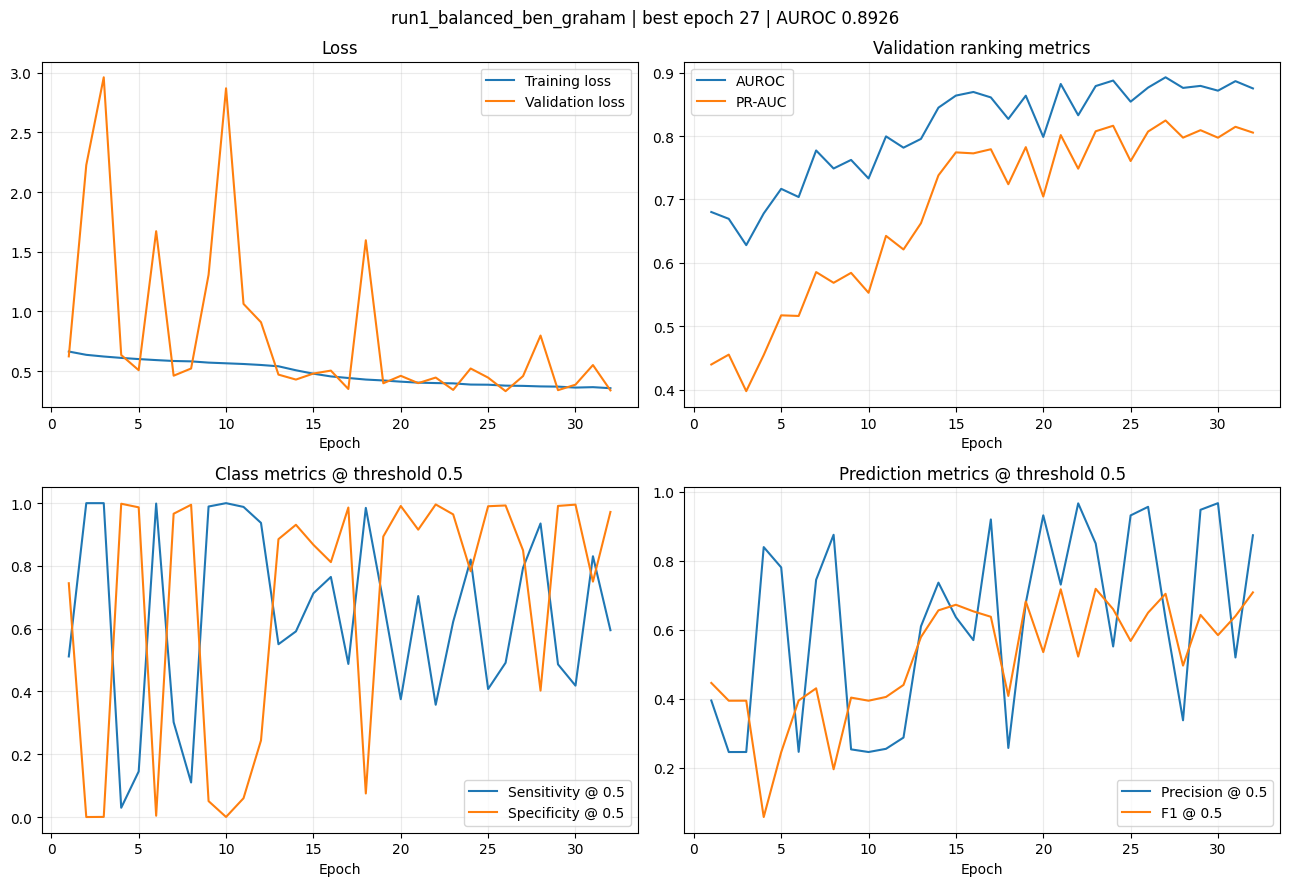

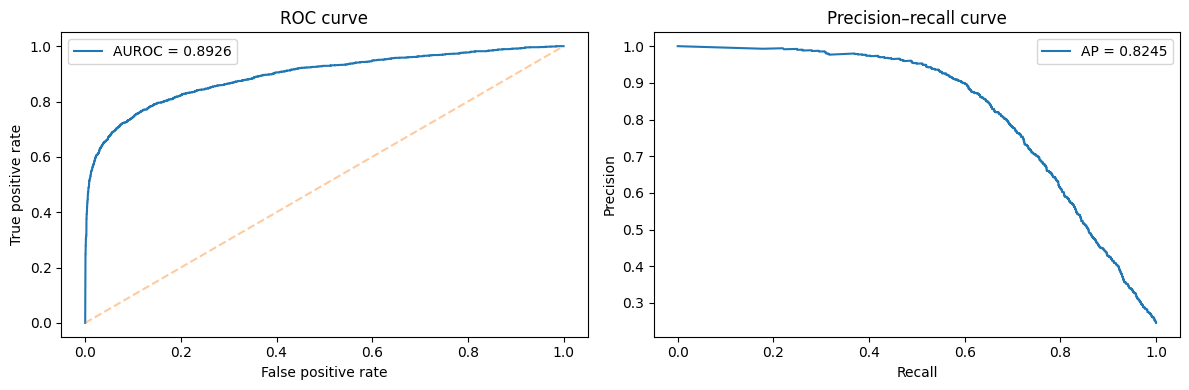

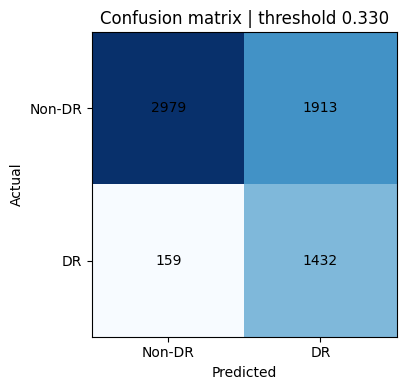


Starting: run2_imbalanced_balanced_batches
train DR share=27.15% | imbalance detected=True | sampler=True
Batch composition: 19 non-DR, 13 DR
run2_imbalanced_balanced_batches epoch=1 train_loss=0.4182 val_loss=3.1496 AUROC=0.6271 sens@0.5=0.0000 spec@0.5=1.0000
  sampler: {'epoch': 1, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_this_epoch': 15161, 'repeated_dr_draws_augmented': 12672, 'total_unique_indices_ever': 55833}
  New best AUROC! checkpoint saved.
run2_imbalanced_balanced_batches epoch=2 train_loss=0.0506 val_loss=1.6405 AUROC=0.6098 sens@0.5=0.0006 spec@0.5=0.9998
  sampler: {'epoch': 2, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_this_epoch': 15161, 'repeated_dr_draws_augmented': 27833, 'total_unique_indices_ever': 55833}
  AUROC not improved: 1/5
run2_imbalanced_balanced_batches epoch=3 train_loss=0.0313 val_loss=1.2596 AUROC=0.6114 sens@0.5=0.8158 spec@0.5=0.3031
  sampler: {'epoch': 3, 'non_dr_draws': 40679, 'dr_draws': 27833, 'unique_dr_seen_t

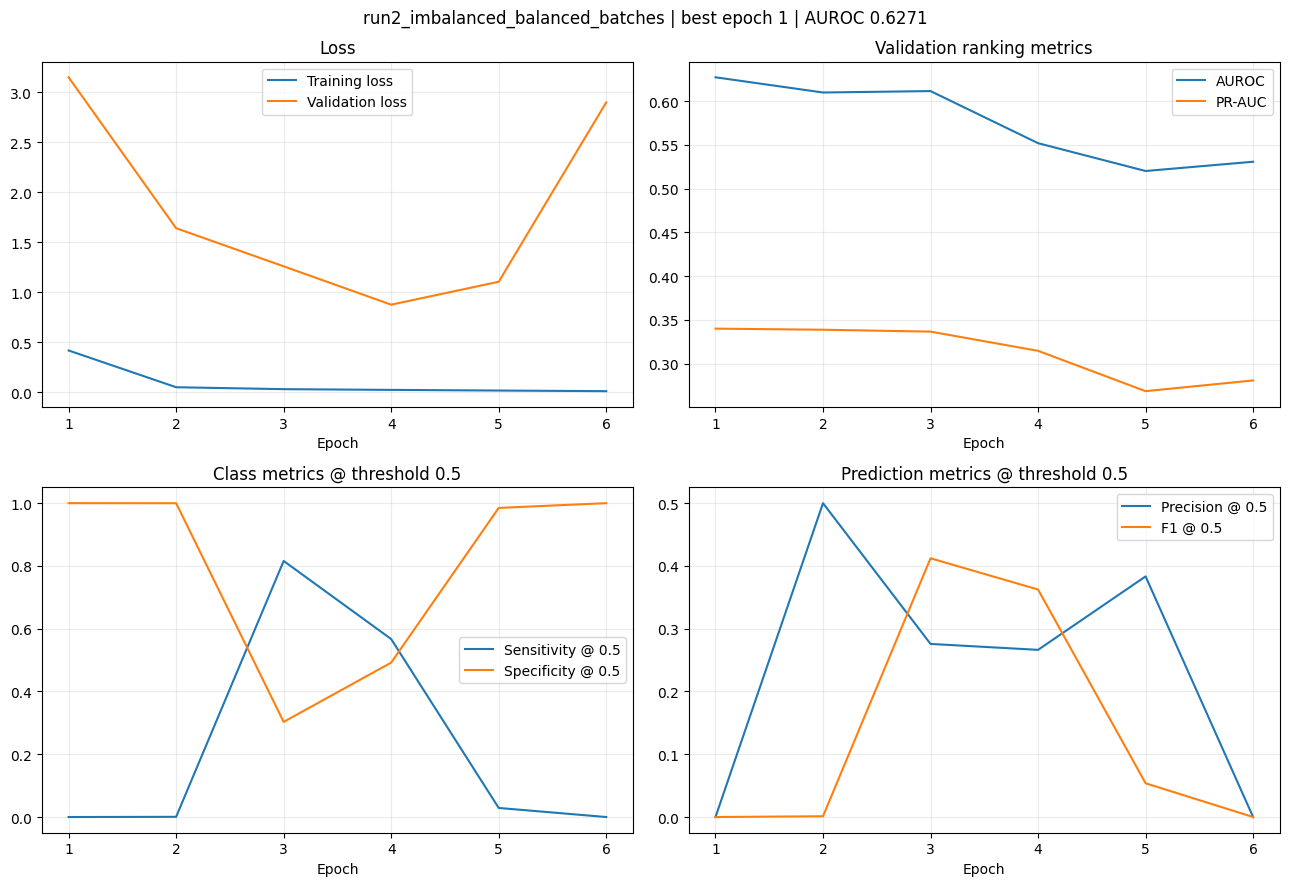

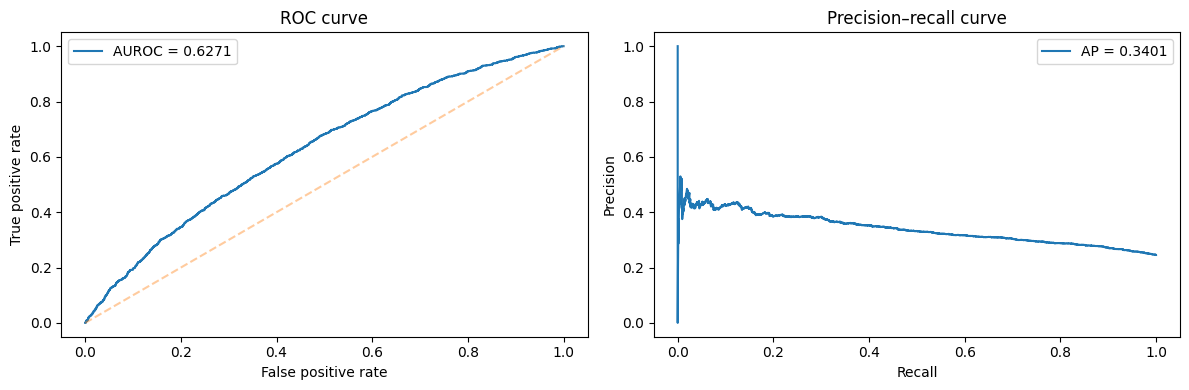

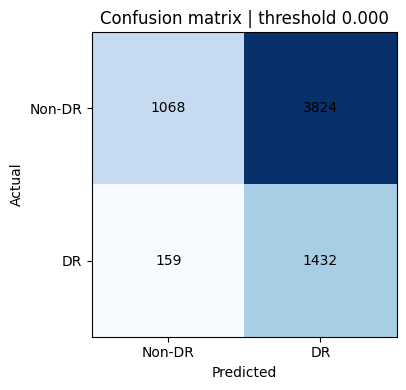

,run,best_epoch,validation_auroc,validation_pr_auc,sensitivity_at_90_target,specificity_at_90_target,threshold
0,run1_balanced_ben_graham,27,0.892650,0.824547,0.900063,0.608953,3.303519e-01
1,run2_imbalanced_balanced_batches,1,0.627138,0.340083,0.900063,0.218316,4.069012e-07


Saved all results and ZIP: /kaggle/working/oculus_plain_bce.zip


In [13]:
RUN_SMOKE_TEST = False

if RUN_SMOKE_TEST:
    print('Training skipped because RUN_SMOKE_TEST=True. Set it to False in the previous cell.')
else:
    results=[]
    for name,frame in [('run1_balanced_ben_graham',balanced),
                       ('run2_imbalanced_balanced_batches',imbalanced)]:
        print('\nStarting:',name)
        summary,history,val_predictions,output=train_run(name,frame)
        save_figures(name,history,val_predictions,summary,output)
        results.append({'run':name,'best_epoch':summary['best_epoch'],
                        'validation_auroc':summary['best_validation_auroc'],
                        'validation_pr_auc':summary['validation_pr_auc'],
                        'sensitivity_at_90_target':summary['at_90pct_sensitivity']['sensitivity'],
                        'specificity_at_90_target':summary['at_90pct_sensitivity']['specificity'],
                        'threshold':summary['threshold_for_90pct_sensitivity']})
    display(pd.DataFrame(results))
    pd.DataFrame(results).to_csv(WORK_ROOT/'comparison.csv',index=False)
    archive=shutil.make_archive(str(WORK_ROOT),'zip',root_dir=WORK_ROOT)
    print('Saved all results and ZIP:',archive)

## 7. Extract an older Kaggle output ZIP, if needed

If you **downloaded a previous Kaggle notebook output as ZIP** and reattached it through *Add Input*, point `PREVIOUS_OUTPUT_ZIP` to that mounted file; its contents will be unpacked into `/kaggle/working/oculus_plain_bce/previous_output`. This is optional. New results are automatically zipped at the end of the training cell.

In [14]:
PREVIOUS_OUTPUT_ZIP = None  # e.g. '/kaggle/input/your-prior-output/output.zip'
if PREVIOUS_OUTPUT_ZIP:
    previous=extract_zip_safely(PREVIOUS_OUTPUT_ZIP, WORK_ROOT/'previous_output')
    print_tree(previous, limit=40)
else:
    print('No previous notebook ZIP selected. New experiment outputs are stored in',WORK_ROOT)

No previous notebook ZIP selected. New experiment outputs are stored in /kaggle/working/oculus_plain_bce


### Research checklist

- [ ] Verify **same patient identities/labels in validation**; verify no patient overlap with either train set.
- [ ] Confirm Run 1 images are actually Ben Graham processed and Run 2 uses the intended preprocessing.
- [ ] Confirm `label=1` means the intended DR definition; grade 1–4 positive is not necessarily referable DR.
- [ ] Capture your Git commit and actual dataset version in the run report.
- [ ] Save `best_model.pt`, `history.csv`, `summary.json`, `best_val_predictions.csv`, `sampling_counts.csv`, and figures.
- [ ] Run final held-out testing only once after comparison rules and threshold are frozen.

**Reporting note:** These two runs alter more than one factor (Ben Graham vs original preprocessing *and* balanced vs imbalanced training), unless both datasets were identically processed. To isolate the effect of imbalance, compare matched preprocessing for both training distributions.